In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import LogFormatter
from mpl_toolkits.mplot3d.art3d import Line3DCollection, Poly3DCollection
import numpy as np

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.preprocessing import StandardScaler

from IPython.display import display, Markdown

from tqdm import tqdm

import copy

from utilities import *

plt.rcParams["axes3d.mouserotationstyle"] = "azel"

In [2]:
### Generate training data

mesh_data = MeshData(n=10)

sampler = FixedTopologySampleGenerator(
    mesh_data,
)

In [3]:
X_train, q_vecs = sampler.sample_batch(2048)

torch.save(
    {
        "X_train": X_train,
        "q_vecs": q_vecs,
    },
    "training data/2048_batch_10x10_train.pt",
)

X_val, q_vecs = sampler.sample_batch(2048)

torch.save(
    {
        "X_train": X_val,
        "q_vecs": q_vecs,
    },
    "validation data/2048_batch_10x10_test.pt",
)

In [4]:
### Train

validation_data_path = "validation data/2048_batch_10x10_test.pt"
validation_data = torch.load(validation_data_path)
validation_ds = TensorDataset(validation_data["X_train"], validation_data["q_vecs"])

topology = MeshData(n=10)

model = ForceDensityPredictorPINN(
    topology=topology,
    act_fn=nn.Tanh(),
    hidden_sizes=(256, 256),
    min_q=0.05,
    max_q=40,
)

In [ ]:
# with profile(activities=[ProfilerActivity.CPU], record_shapes=True) as prof:
history = train_adaptive(
    model=model,
    data_loss_fn=pointwise_Lp_loss,
    data=validation_ds,
    data_generator=sampler,
    refresh_every=1,
    data_loss_parameters=(2.0,),
    train_val_test=(0, 0.5, 0.5),
    batch_size=128,
    batches_per_epoch=20,
    physics_loss_fn=FDM_physics_loss,
    t_colloc=None,
    physics_loss_parameters=(),
    epochs=5000,
    lr=1e-2,
    optimizer=torch.optim.Adam,
    optimizer_params={"fused": True},
    weighting=SigmoidWeighting(),
    early_stop_patience=100,
)

# print(
#     prof.key_averages(group_by_input_shape=True).table(
#         sort_by="self_cpu_time_total", row_limit=20
#     )
# )

tensor([0.0846, 0.1301, 0.1103,  ..., 0.0755, 0.0663, 0.1268],
       grad_fn=<AmaxBackward0>)
tensor(0.4202, grad_fn=<MaxBackward1>)
tensor(502)
(9, 100, 3)


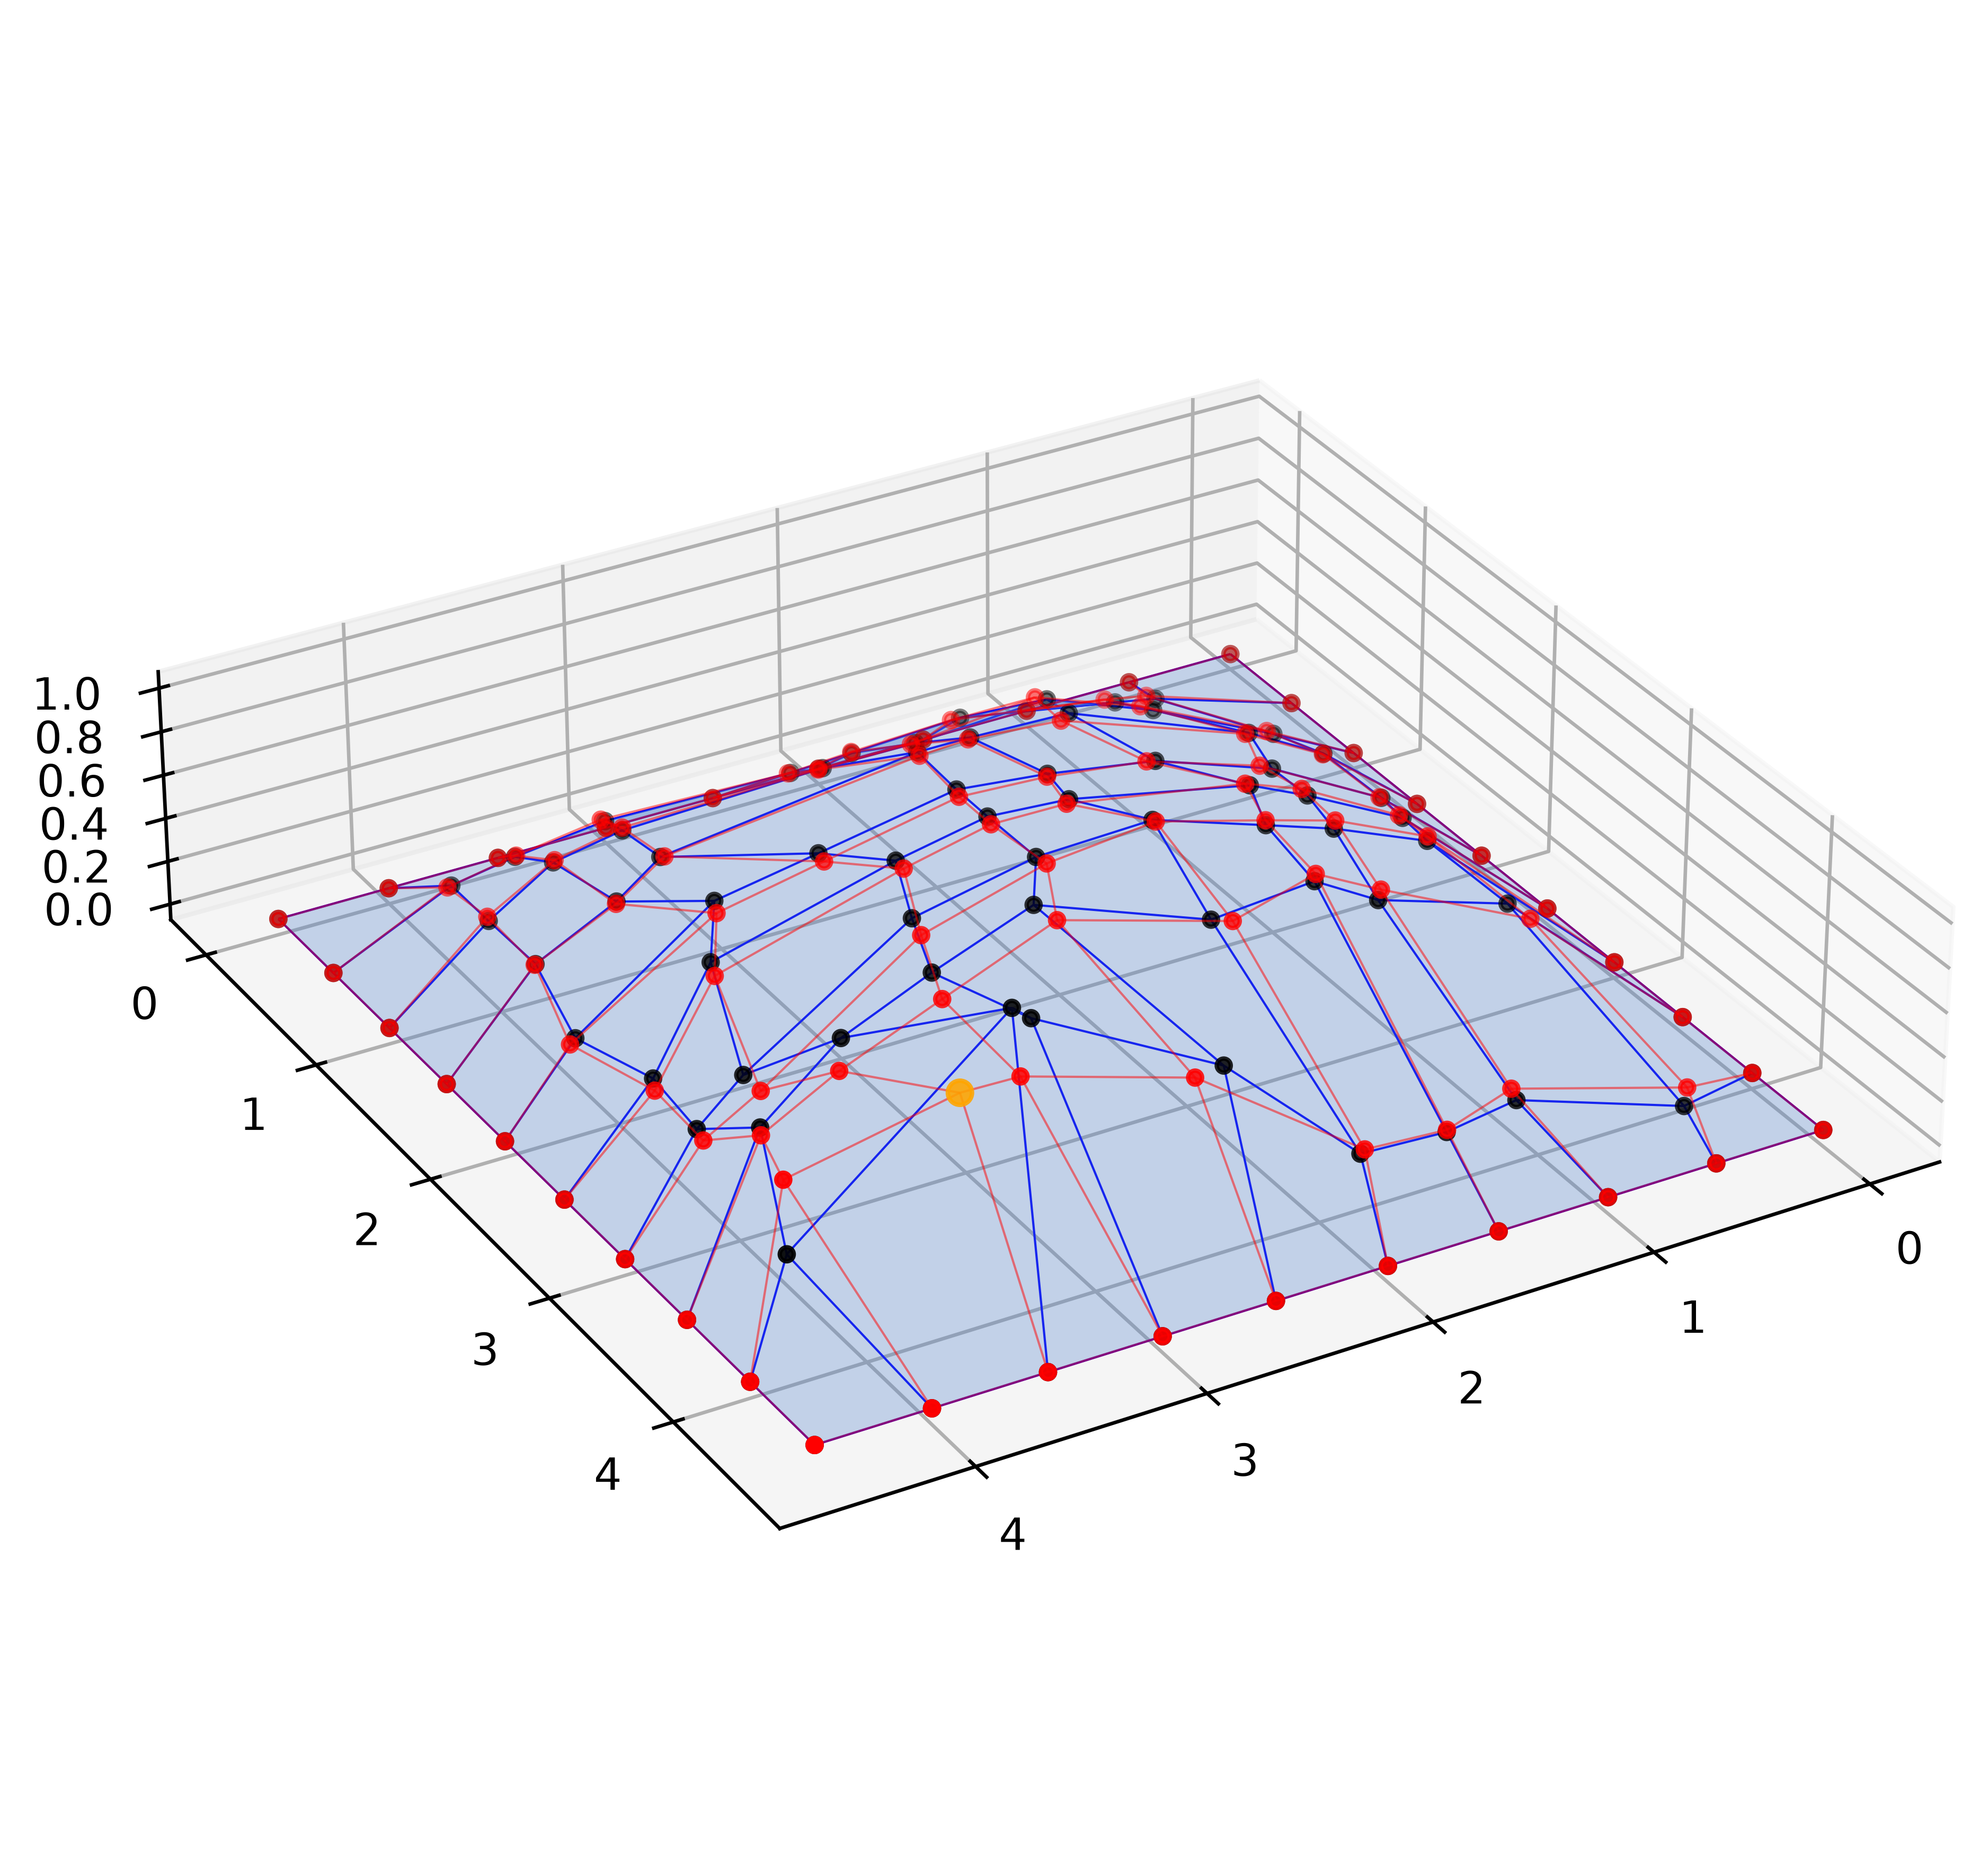

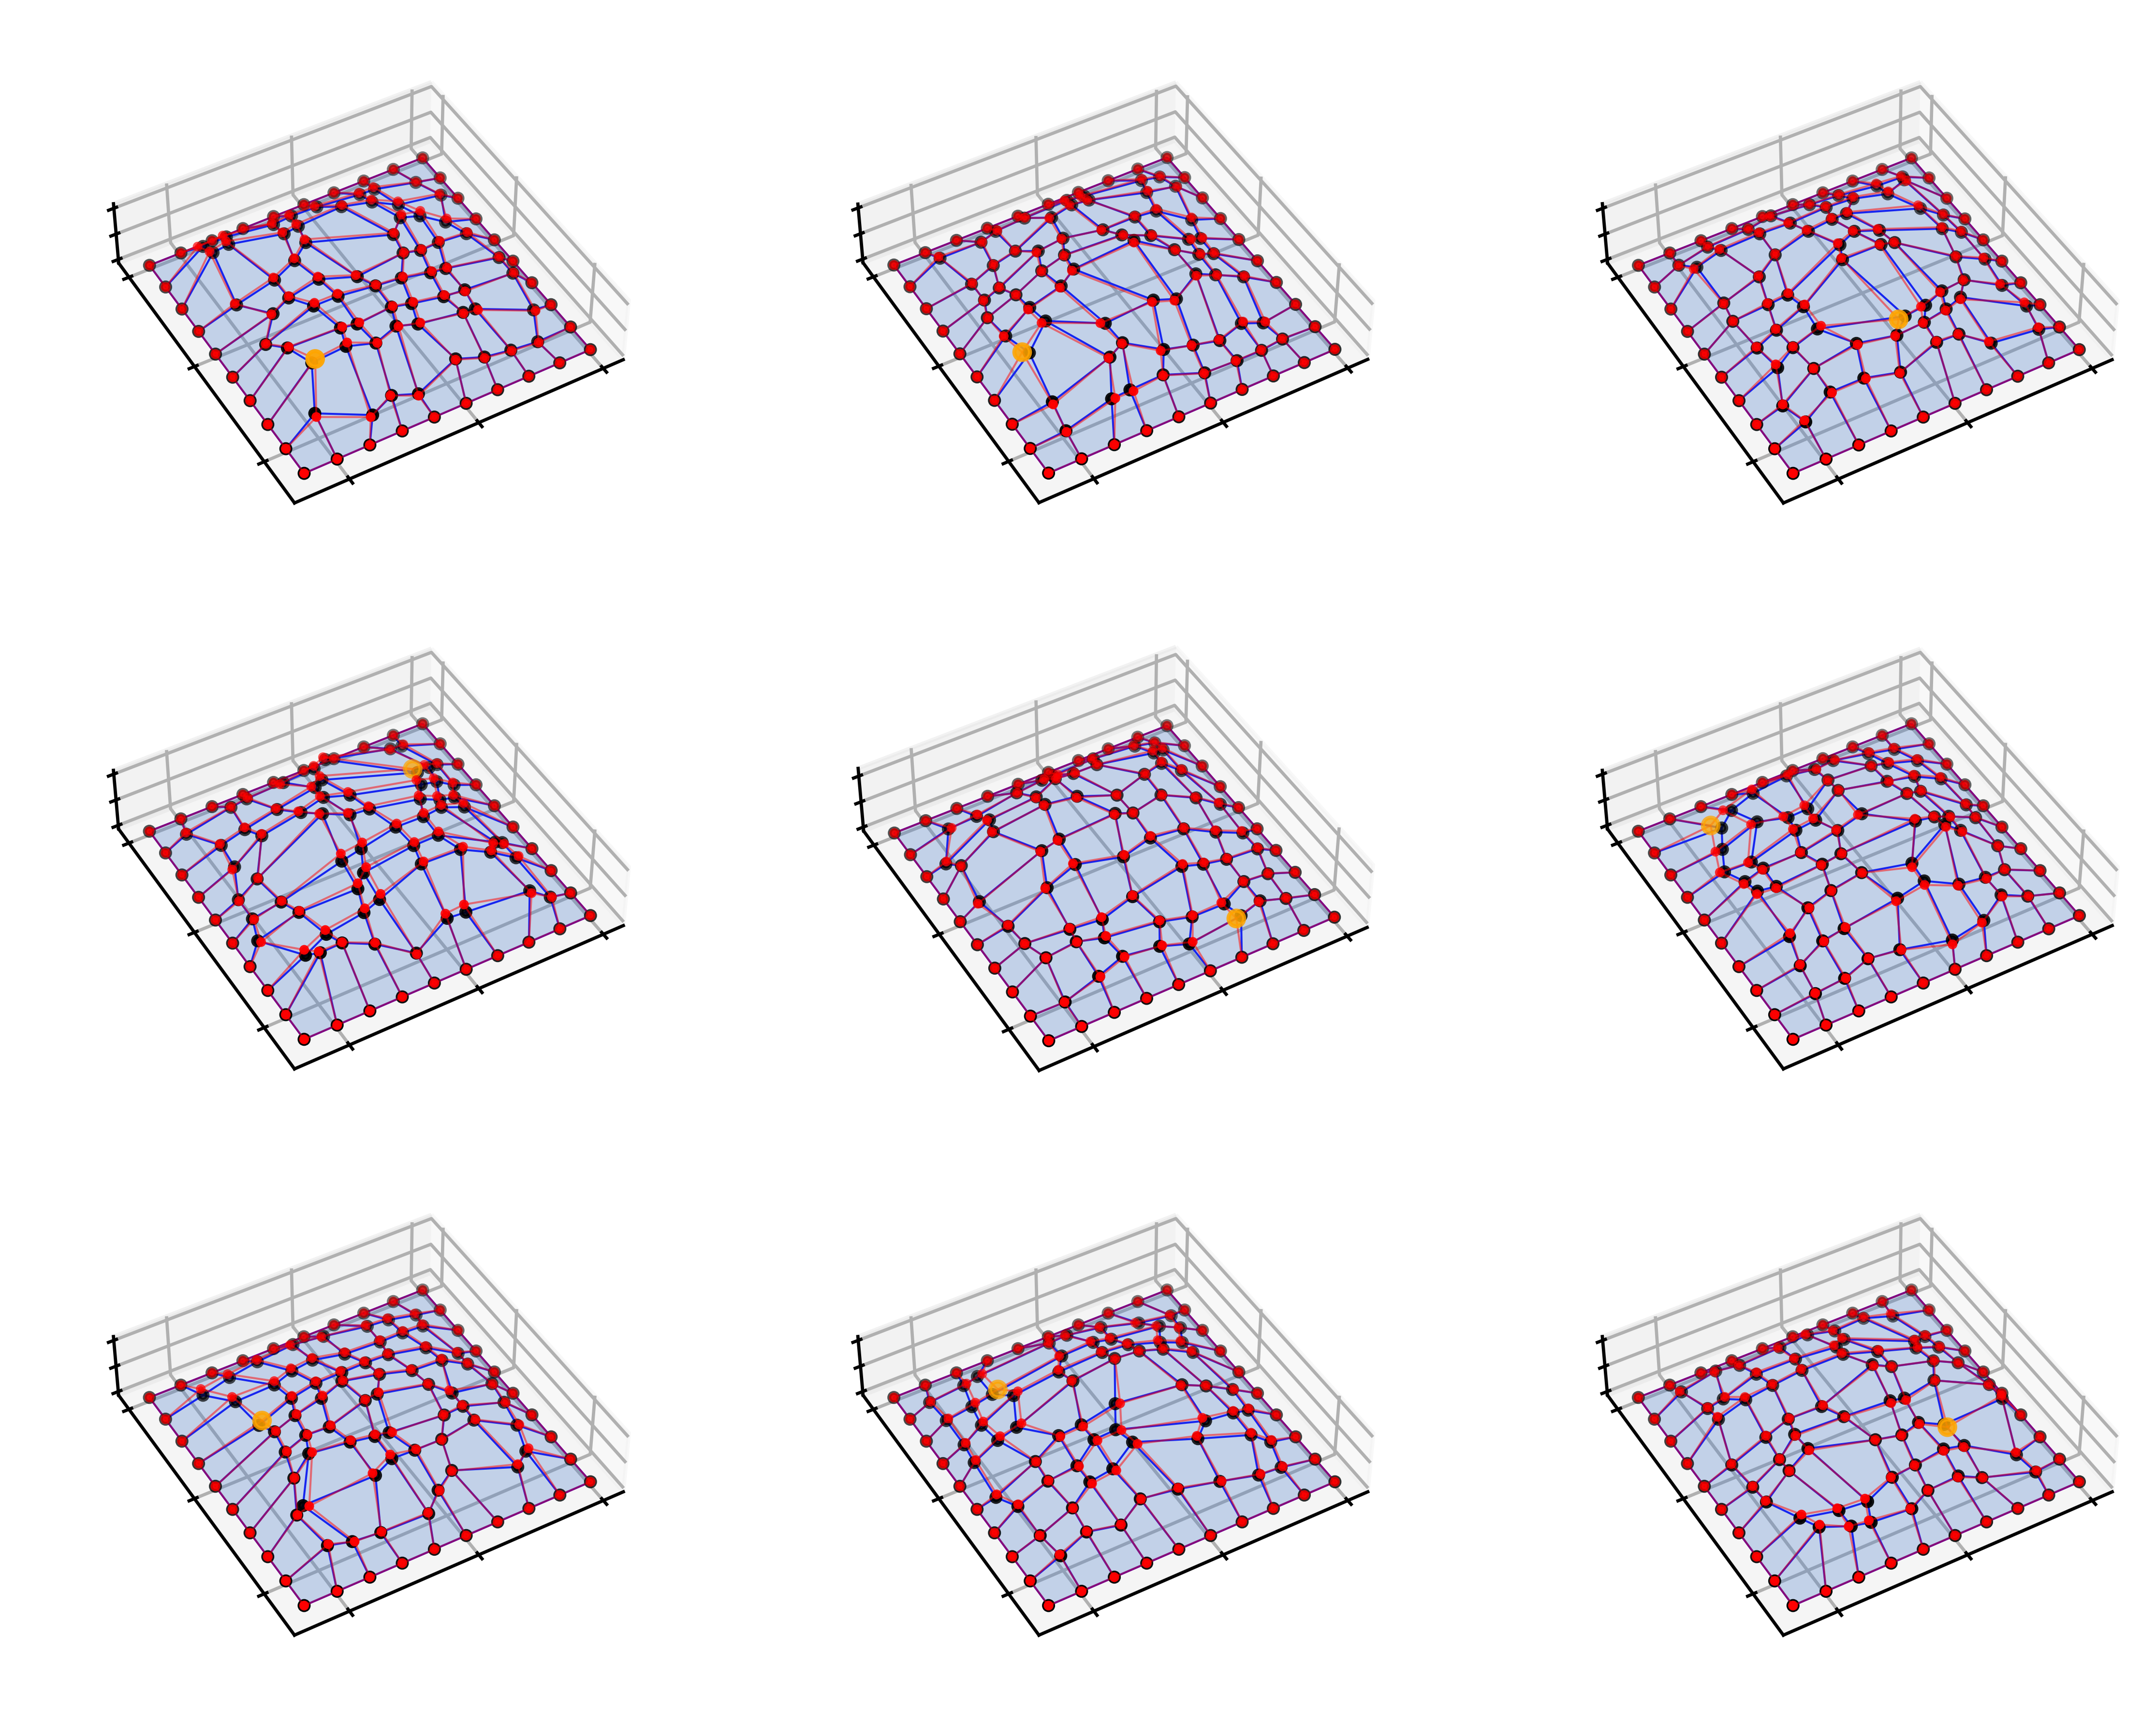

In [18]:
p_mats = validation_data["X_train"][:, topology.free_ind, 4:]
hat_qs = model(
    validation_data["X_train"].reshape((validation_data["X_train"].shape[0], -1))
)
hat_X = topology.eq_shape_batched(hat_qs, p_mats)
X = validation_data["X_train"][:, :, :3]

err = torch.linalg.norm((hat_X - X), dim=2).amax(dim=1)

print(err)
print(torch.max(err))

max_err_row = torch.argmax(err)

print(max_err_row)

Xs_0 = validation_data["X_train"][max_err_row, :, :]
qs_0 = validation_data["q_vecs"][max_err_row, :]
P_mat_0 = Xs_0[topology.free_ind, 4:]

qs_hat = model(Xs_0.ravel())

X_eq = Xs_0[:, :3]  # topology.eq_shape(qs_0, P_mat_0)
X_hat = topology.eq_shape(qs_hat, P_mat_0)

# %matplotlib qt
fig, ax = visualize_mesh(topology, X_eq, X_hat, (30, 60))

#####

Xs_viz = validation_data["X_train"][:9, :, :]
qs_viz = validation_data["q_vecs"][:9, :]
P_mat_viz = Xs_viz[:, topology.free_ind, 4:]

qs_hat_viz = model(Xs_viz.reshape(Xs_viz.shape[0], -1))

X_eq_viz = Xs_viz[:, :, :3]
X_hat_viz = topology.eq_shape_batched(qs_hat_viz, P_mat_viz).detach().numpy()

fig, axs = visualize_mesh_batch(
    topology,
    X_eq_viz,
    X_hat_viz,
    (45, 60),
)

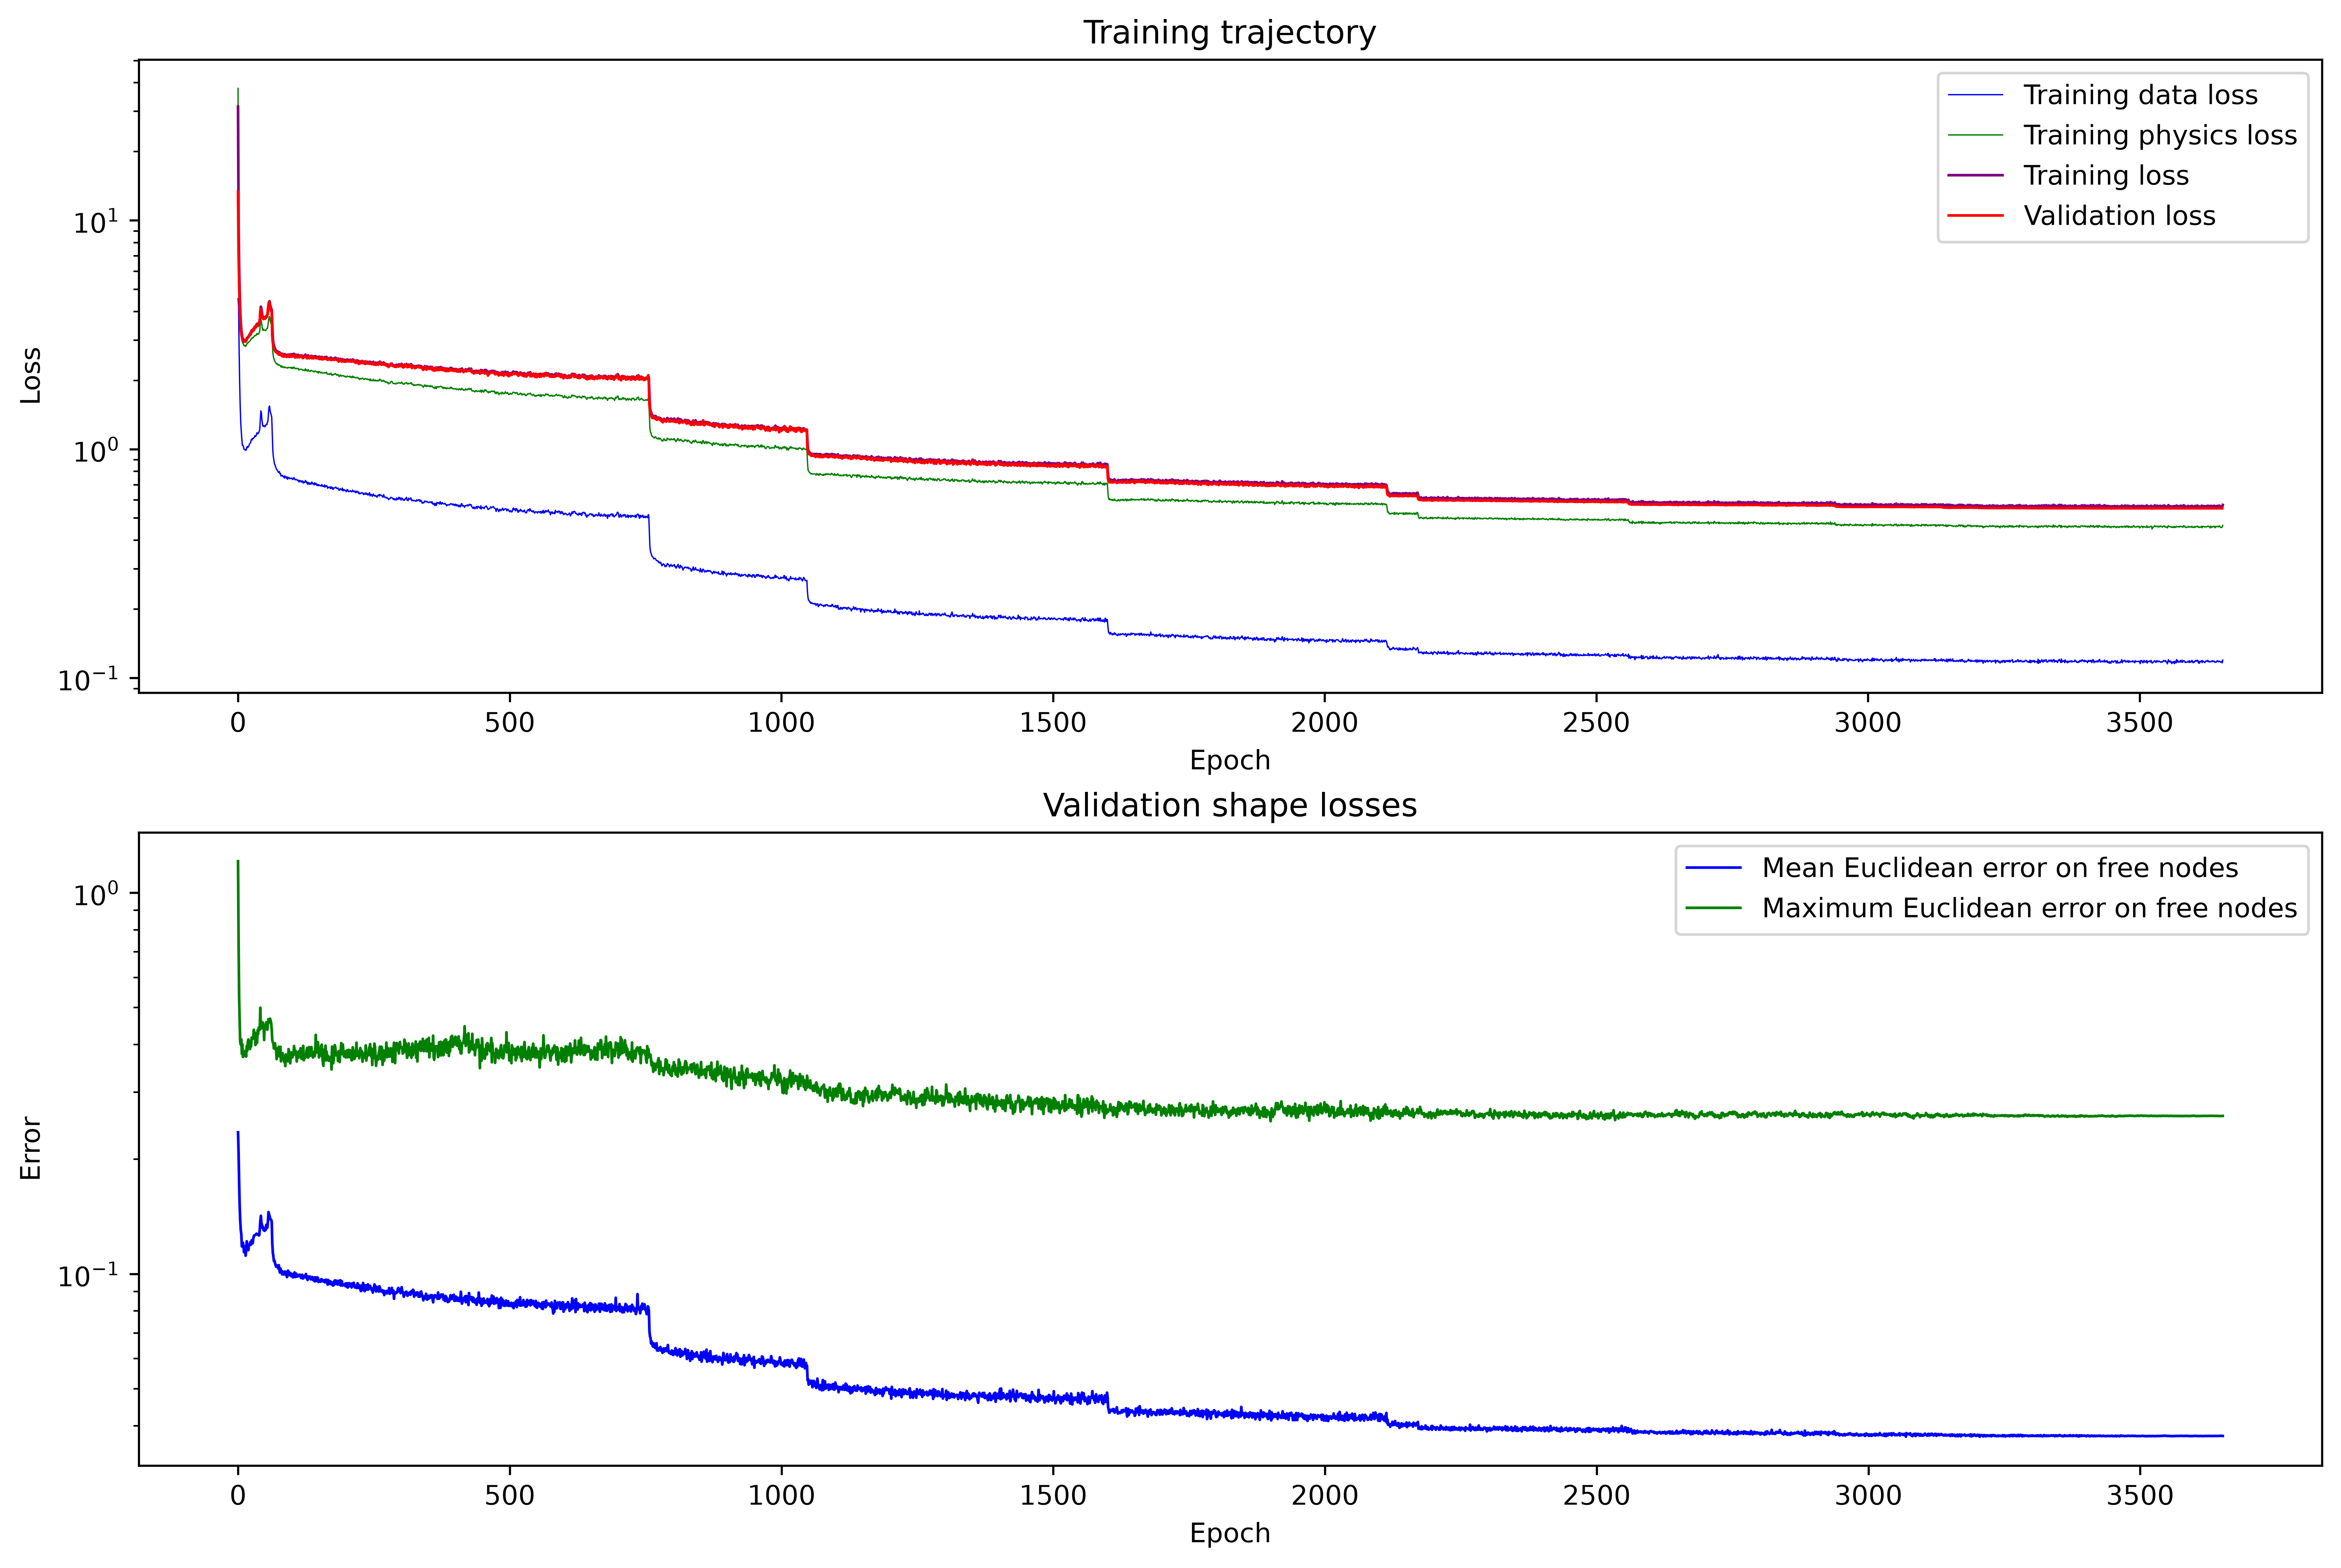

In [19]:
plt.close('all')
%matplotlib inline

fig, axs = plt.subplots(2, 1, figsize=(12, 8), layout = "constrained", dpi = 600)

###

axs[0].plot(
    history["data_train"],
    color="blue",
    lw=0.5,
    label="Training data loss",
)
axs[0].plot(
    history["physics_train"],
    color="green",
    lw=0.5,
    label="Training physics loss",
)

axs[0].plot(
    history["total_train"],
    color="purple",
    lw=1.0,
    label="Training loss",
)

axs[0].plot(
    history["total_val"],
    color="red",
    lw=1.0,
    label="Validation loss",
)
axs[0].set_title("Training trajectory")
axs[0].set_xlabel("Epoch")
axs[0].set_ylabel("Loss")
axs[0].legend()

axs[0].set_yscale("log")

###

axs[1].plot(
    history["mean_dist_val"],
    color="blue",
    lw=1.0,
    label="Mean Euclidean error on free nodes",
)

axs[1].plot(
    history["max_dist_val"],
    color="green",
    lw=1.0,
    label=r"Maximum Euclidean error on free nodes",
)

axs[1].set_xlabel("Epoch")
axs[1].set_ylabel("Error")

axs[1].set_title("Validation shape losses")
axs[1].set_yscale("log")
axs[1].legend()

# fig.tight_layout()

In [ ]:
topology = MeshData(n=10)

from matplotlib.lines import Line2D
from matplotlib.ticker import LogFormatter

activations = [nn.Tanh(), nn.GELU(), nn.SiLU()]
hidden_layer_sizes = [128, 256, 512, 1024]
num_hidden_layers = [2, 3, 4, 6]
loss_norms = [1.0, 1.5, 2.0]

##### hyperparameter tuning -- find which of these models performs the best!

plt_colors = {
    0: "red",
    1: "blue",
    2: "green",
}

handles = []
for ind, color in plt_colors.items():
    handles.extend(
        [
            Line2D(
                [0],
                [0],
                color=(color, 0.25),
                linestyle="-",
                label=rf"$\mathcal{{L}}^{{{loss_norms[ind]}}}$, train loss",
            ),
            Line2D(
                [0],
                [0],
                color=(color, 1.0),
                linestyle="-",
                label=rf"$\mathcal{{L}}^{{{loss_norms[ind]}}}$, val loss",
            ),
            Line2D(
                [0],
                [0],
                color=(color, 1.0),
                linestyle="--",
                label=rf"$\mathcal{{L}}^{{{loss_norms[ind]}}}$, val shape loss",
            ),
        ]
    )


def e_fmt(v):
    mant, exp = f"{v:.0e}".split("e")
    return f"{mant}e{int(exp)}"


class ELogFormatter(LogFormatter):
    def __call__(self, x, pos=None):
        if not super().__call__(x, pos):  # LogFormatter returns "" for ticks it hides
            return ""
        return e_fmt(x)


histories = {}

for i, activation in enumerate(activations):
    fig, axs = plt.subplots(
        len(hidden_layer_sizes),
        len(num_hidden_layers),
        sharey=True,
        layout="constrained",
        figsize=(6.5, 8),
        dpi=600,
    )

    for ax in axs.flat:
        ax.tick_params(axis="x", bottom=False, labelbottom=False)

    # create twin axes for plotting shape losses
    # because they're on a different scale

    twins = np.array([ax.twinx() for ax in axs.flat]).reshape(axs.shape)

    for ax in [*axs.flat, *twins.flat]:
        ax.set_yscale("log")
        ax.yaxis.set_major_formatter(ELogFormatter())
        ax.yaxis.set_minor_formatter(ELogFormatter(minor_thresholds=(1, 0.4)))
        ax.tick_params(
            axis="y",
            which="both",
            labelsize=8,
            labelrotation=45,
            labelrotation_mode="ytick",
        )

    for tw in twins.flat[1:]:
        tw.sharey(twins.flat[0])

    for tw in twins[:, :-1].flat:
        tw.tick_params(which="both", labelright=False)

    fig.get_layout_engine().set(wspace=0.02, w_pad=0.02, rect=(0, 0, 0.94, 1))

    leg = fig.legend(
        handles=handles,
        loc="outside upper center",
        title=rf"{activation._get_name()} activation",
        title_fontsize=14,
        frameon=False,
        ncol=3,
    )

    # leg.get_title().set_fontweight("bold")

    # fig.suptitle(rf"{activation._get_name()} activation")
    fig.supylabel("Training Loss")
    fig.text(
        0.99,
        0.5,
        r"Shape loss (mean $\mathcal{L}^2$ error per node)",
        rotation=270,
        va="center",
        ha="right",
        fontsize="large",
    )
    fig.supxlabel("Epoch")

    for j, size_hidden in enumerate(hidden_layer_sizes):
        for k, num_hidden in enumerate(num_hidden_layers):
            model_name = f"{activations[i]._get_name()} activation -- {num_hidden_layers[j]} hidden layers of size {hidden_layer_sizes[k]}"
            histories[model_name] = {}

            axs[j, k].set_title(
                rf"{num_hidden} $\times$ {size_hidden}", fontsize="small"
            )

            for l, loss_norm in enumerate(loss_norms):
                model = ForceDensityPredictorPINN(
                    topology=topology,
                    act_fn=activation,
                    hidden_sizes=tuple(size_hidden for n in range(num_hidden)),
                    min_q=0.05,
                    max_q=40,
                )

                model_history = train_adaptive(
                    model=model,
                    data_loss_fn=pointwise_Lp_loss,
                    data=validation_ds,
                    data_generator=sampler,
                    refresh_every=1,
                    data_loss_parameters=(loss_norm,),
                    train_val_test=(0, 0.5, 0.5),
                    batch_size=128,
                    batches_per_epoch=20,
                    # physics_loss_fn=FDM_physics_loss,
                    t_colloc=None,
                    physics_loss_parameters=(),
                    epochs=10,
                    lr=1e-2,
                    optimizer=torch.optim.Adam,
                    optimizer_params={"fused": True},
                    weighting=SigmoidWeighting(),
                    early_stop_patience=100,
                )

                histories[model_name][loss_norm] = model_history

                axs[j, k].plot(
                    model_history["total_train"],
                    color=(plt_colors[l % len(loss_norms)], 0.25),
                    lw=0.75,
                )

                axs[j, k].plot(
                    model_history["total_val"],
                    color=(plt_colors[l % len(loss_norms)], 1.0),
                    lw=0.75,
                )

                twins[j, k].plot(
                    model_history["mean_dist_val"],
                    color=(plt_colors[l % len(loss_norms)], 1.0),
                    lw=0.75,
                    ls="--",
                )

    plt.savefig(
        f"{activation._get_name()} activation.png", dpi=600, bbox_inches="tight"
    )

Training:   0%|          | 0/10 [00:00<?, ?it/s]/Users/wonuola/Documents/Obsidian/Stanford Fa26/Fa26/CEE 292/Project 1/src/utilities.py:1098: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /Users/runner/work/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:821.)
  history["data_weight"].append(float(w_data))
Training:  90%|█████████ | 9/10 [00:03<00:00,  2.34it/s, Train=2.647893, Val=2.668198]